# 04. Forced photometry on your own ground-based image

Use this notebook as a template when you have an image from another
telescope and want to measure its fluxes with the Euclid VIS source models
as the prior: the VIS positions and shapes are kept fixed, convolved with
your image's PSF, and only the fluxes are fitted.

The worked example is a 200-arcsec SDSS $g$ image centred on RA = 265.8432,
Dec = 64.9650. **To use your own data, replace the files read in section 1**;
everything after that runs unchanged, as long as your image overlaps the
Euclid footprint. You need:

- a science image with a celestial WCS in its header;
- a 1σ uncertainty image on the same pixels (or a variance image, as here,
  of which you take the square root);
- the flux unit of one pixel value, e.g. `u.nanomaggy`, `u.uJy`, or a
  calibrated quantity such as `4.7 * u.nJy` per count;
- a PSF stamp (odd-sized, any normalisation). Without one, `gb.gaussian_psf`
  makes a Gaussian placeholder from the seeing FWHM, and section 4 can
  build the PSF from stars in your image instead.

A ground image can have a more variable PSF and sky than a space image, so
we first check its astrometry and PSF against stars in the field. SDSS has
already subtracted a sky estimate, so the example fit makes no additional
sky subtraction; set `BACKGROUND_METHOD = "sep"` in section 7 if your image
still contains sky. Section 11 demonstrates the background subtraction with
an injected sky map. Once the steps below
work for your image, the whole fit runs in one call through
`ep.run_forced_photometry(..., ground_images={"g": inputs})`, or from the
command line with `euclid-phot run --ground-image ...`.

In [1]:
DATA_ACCESS = "DR1"  ## Choose "DR1" or "Q1".
import euclid_phot as ep
ep.set_data_access(DATA_ACCESS)

from euclid_phot import forced, ground_based as gb
from dataclasses import replace
import time

import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.table import Table
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

from euclid_phot.sources import clone_sources
from euclid_phot.tractor_image import make_tractor_image
from euclid_phot.units import UJY_PER_NMGY

DATA_DIR = ep.get_data_dir()  ## Euclid download cache; set EUCLID_PHOT_DATA_DIR to move it
GROUND_DIR = DATA_DIR / "ground_based"  ## the SDSS example lands here; point it at your own files
OUTPUT_DIR = DATA_DIR.parent / "output" / "ground_based"  ## examples/output/ground_based
N_WORKERS = 8

## 1. Input image

**Replace this cell with your own data.** Put your files in `GROUND_DIR` (or
point the paths anywhere) and define `sci_data`, `sci_header` (for
`sci_wcs`), the 1σ uncertainty `unc_data`, the PSF stamp `psf_data`, and
`science_unit`, the flux of one pixel value. Below, `make_image` gets a band
label (`band="g"`), which names the output columns, e.g. `flux_g_ujy`.

`make_image` converts the science and uncertainty to µJy/pixel, the unit of
every band in this package. To fit several bands, run this notebook once per
band: the VIS models of section 5 are the same for all of them.

**Example inputs**: one frame of SDSS DR17 (run-camcol-field 6122-5-153),
downloaded from the SDSS archive by `gb.fetch_sdss_example` on the first run
and cached under `examples/native_data/ground_based/`, as four files:

- Science: `SDSS_265.8432_64.9650_g_200_sci.fits` (nanomaggies/pixel)
- Variance: `SDSS_265.8432_64.9650_g_200_var.fits`
- PSF: `SDSS_265.8432_64.9650_g_200_psf.fits` (from the SDSS psField model)
- Catalog for comparison: `SDSS_265.8432_64.9650_g_200_cat.ecsv` (SDSS PhotoObj)

The SDSS catalog is used only to check the measurements (section 8); with
your own data, compare with whatever catalog exists for it, or skip that
section.

The same function makes these four files for any position in the SDSS
footprint: pass `ra`, `dec`, `size_arcsec` and `band`, and it looks up the
SDSS frame covering that cutout on SkyServer.

In [2]:
# Your data: replace these four files and the unit below.
# The SDSS example is downloaded on the first run; any SDSS position works: ra=, dec=, size_arcsec=, band=.
example = gb.fetch_sdss_example(GROUND_DIR, force=True)
sci_data, sci_header = fits.getdata(example.science, header = True)
unc_data = np.sqrt( fits.getdata(example.variance) )
psf_data = fits.getdata(example.psf)
sci_wcs = WCS(sci_header).celestial

print(sci_header['BUNIT'])
# Flux of one pixel value: SDSS frames are in nanomaggies.
science_unit = u.nanomaggy


# Without a PSF stamp, a Gaussian of the seeing FWHM can stand in for psf_data:

from euclid_phot.units import pixel_scale_arcsec

psf_data_filler = gb.gaussian_psf( fwhm_arcsec=1.4,  # replace with the image's measured seeing
                                   pixel_scale_arcsec=pixel_scale_arcsec(sci_wcs),
                                 ) 
# psf_data = psf_data_filler

SDSS DR17 frame 6122-5-153 (g): downloading what is missing


the RADECSYS keyword is deprecated, use RADESYSa. [astropy.wcs.wcs]


wrote SDSS_265.8432_64.9650_g_200_{sci,var,psf}.fits and SDSS_265.8432_64.9650_g_200_cat.ecsv (94 objects) to /Users/ianlin/Desktop/euclid-forced-photometry-dev/examples/data/dr1/deep_survey/ground_based
nanomaggy/pixel


### Take a look at the data



505 × 505 pixels; 0.396″/pixel; band g
Footprint ≈ 200.0″ × 200.0″
PSF stamp (51, 51), sum 1.000000


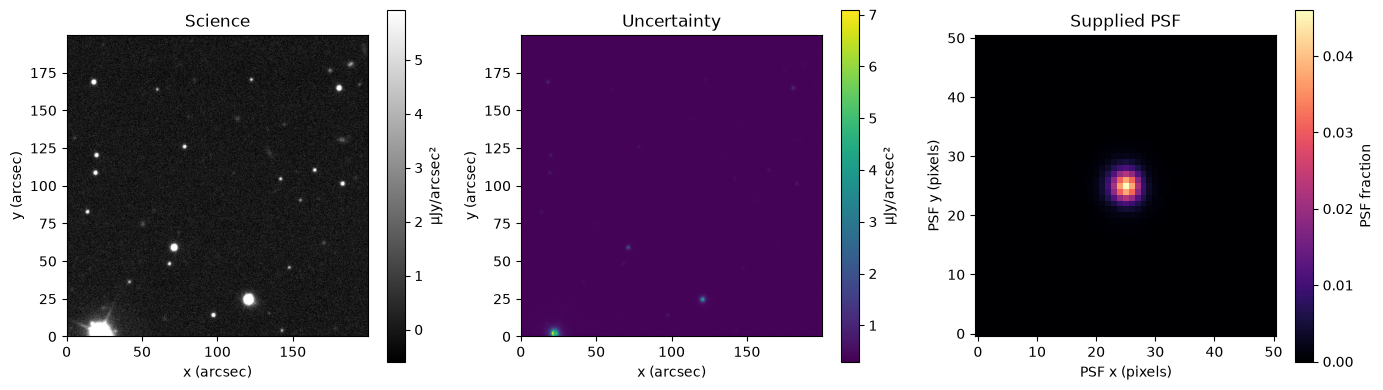

In [3]:
inputs = gb.make_image(sci_data, unc_data, psf_data, science_unit, sci_wcs, band="g")
image = inputs.image
ny, nx = image.science_ujy.shape
print(f"{nx} × {ny} pixels; {inputs.pixel_scale_arcsec:.3f}″/pixel; band {image.band}")
print(f"Footprint ≈ {nx*inputs.pixel_scale_arcsec:.1f}″ × {ny*inputs.pixel_scale_arcsec:.1f}″")
print(f"PSF stamp {image.psf.shape}, sum {image.psf.sum():.6f}")
gb.show_inputs(inputs)
plt.show()

*The input image: the science frame, its RMS, and the normalized PSF stamp, with colorbars and
an angular scale.*

## 2. Euclid VIS image and MER sources

This cell reuses the VIS science, RMS, flag, GRID PSF and MER catalog cached in `DATA_DIR`, and downloads whatever is missing. The VIS box covers the ground image plus a small margin (220 arcsec here). We show VIS next to SDSS, with the MER sources as cyan circles.

MER: querying Euclid for the image footprint


/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/ground_based/prior.py:62: UserWarning: DR1 morphology_table is not configured in src/conf.json; Sersic shape columns are masked. The existing source builder uses its isophotal/exponential fallback; tree-selected shapes are still fitted to the VIS pixels.
  mer = query_mer_catalog(ra, dec, size / 7200)


MER: saved mer_catalog_265.8432_64.9650_220.fits
VIS science/RMS/flag: ready
VIS GRID PSF: ready
Center: 265.8432°, +64.9650°; VIS box: 220″
MER sources: 3223; catalog: mer_catalog_265.8432_64.9650_220.fits


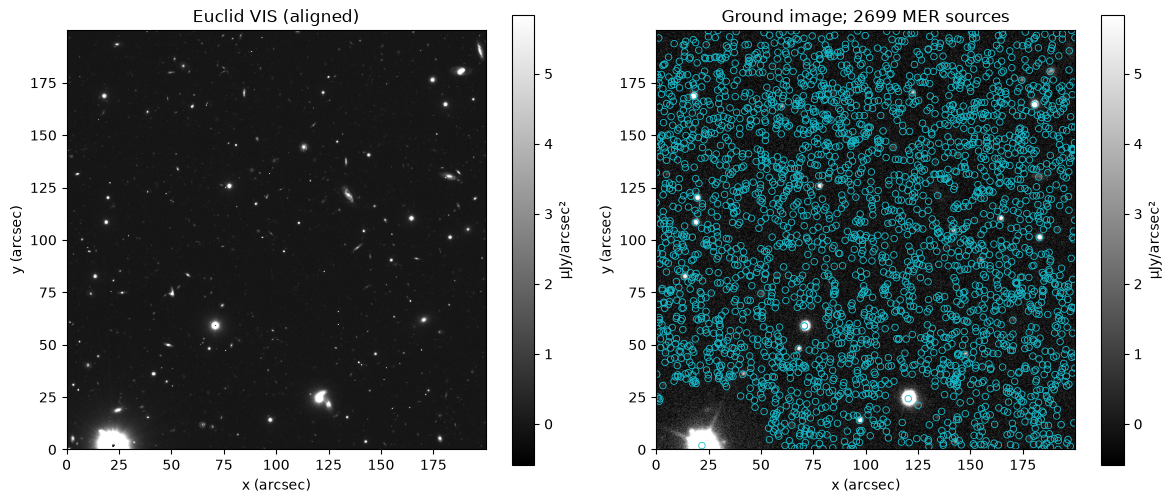

In [4]:
euclid = gb.prepare_euclid(image, DATA_DIR, force_download=True)
print(f"Center: {euclid.ra:.4f}°, {euclid.dec:+.4f}°; VIS box: {euclid.size_arcsec:.0f}″")
print(f"MER sources: {len(euclid.mer)}; catalog: {euclid.mer_path.name}")
gb.show_scene(inputs, euclid)
plt.show()

*VIS and the ground image on the same WCS and surface-brightness scale, with the MER sources
as cyan circles on the ground image.*

## 3. Check the image WCS

Match bright, isolated stars in the ground image to MER stars and refit
the WCS from their centroids with Astropy, so that the VIS positions land
on the right pixels of the ground image.


Matched stars: 15
Median offset: 0.233″ before → 0.091″ after


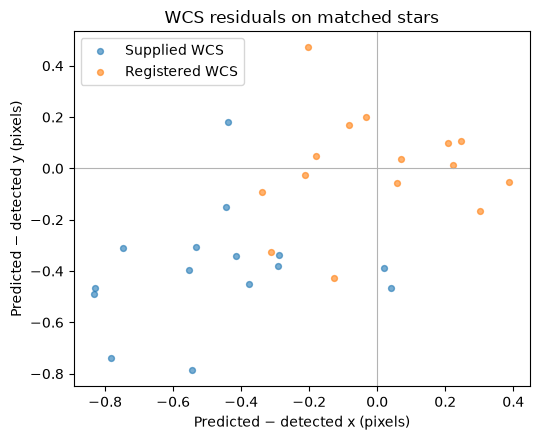

In [5]:
registration = gb.register_image(image, euclid.mer, min_matches=10)
print(f"Matched stars: {registration.n_used}")
print(f"Median offset: {registration.median_before_arcsec:.3f}″ before → "
      f"{registration.median_after_arcsec:.3f}″ after")
image = replace(image, wcs=registration.wcs)
inputs = replace(inputs, image=image)
gb.show_registration(registration)
plt.show()

*Position residuals, predicted minus detected, for the matched stars with the supplied WCS and
with the registered WCS.*

## 4. Check PSF vs. stars

Compare the supplied PSF with the bright, isolated stars in the image.
The example field has 10 such stars; four are shown. The radial profile
of the PSF follows the stars out to 3 to 4 arcsec, beyond which the sky
noise dominates.


Usable stars: 9; recommendation: supplied
FWHM: supplied 5.45 pixels; image stars 5.82 pixels
We have 9 stars.


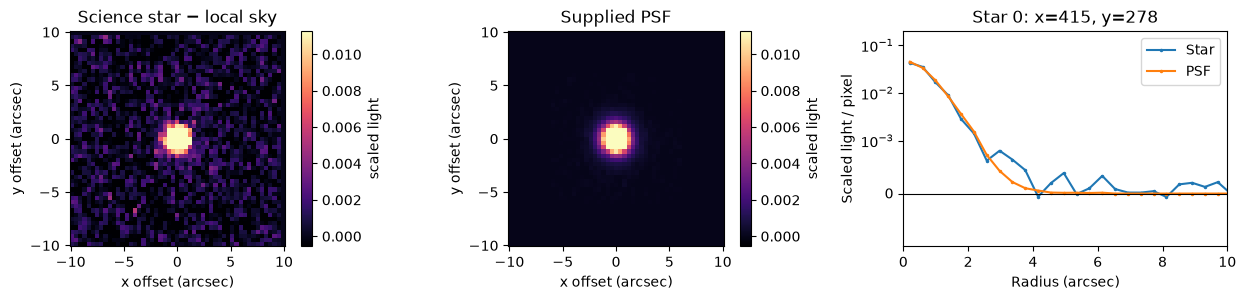

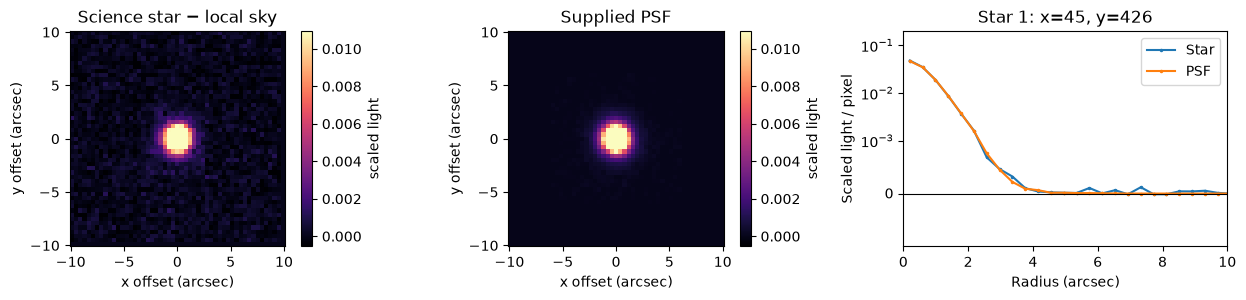

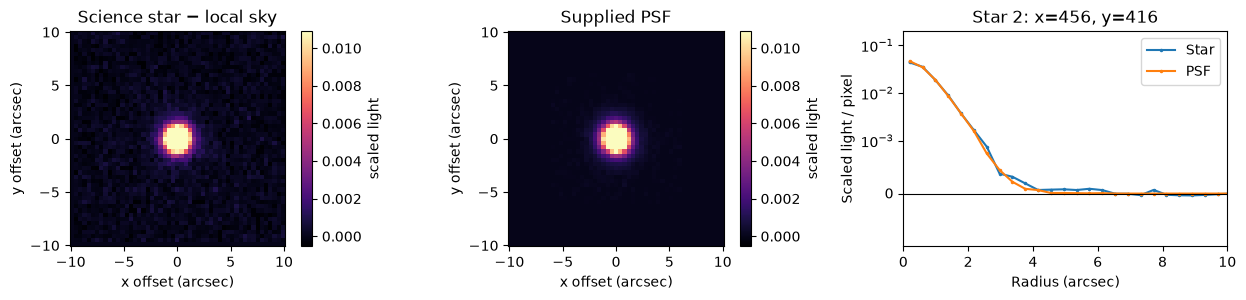

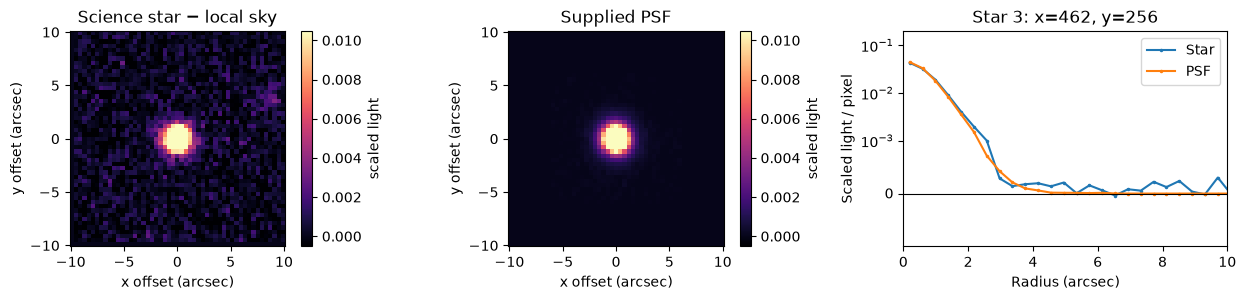

In [6]:
psf_check = gb.assess_psf(image, registration)
print(f"Usable stars: {len(psf_check.stars)}; recommendation: {psf_check.recommendation}")
if psf_check.empirical_psf is not None:
    print(f"FWHM: supplied {psf_check.supplied_fwhm_pix:.2f} pixels; "
          f"image stars {psf_check.observed_fwhm_pix:.2f} pixels")
    
print(f"We have {len(psf_check.stars)} stars.")
for i in range(4):
    gb.show_psf_stars(image, psf_check, star_index=i)
    plt.show()

*Four of the bright isolated stars next to the supplied PSF, with their radial profiles.*

### Choose the ground-image PSF

Choose the PSF for the forced photometry fitting. `"supplied"` uses the PSF stamp read in section 1; `"nearest_star"` uses the closest usable image star to each fitted region, after local sky removal and smoothing its noisy outer wings. The star numbers in the figures above identify stars you can exclude. If the PSF changes within one fitted region, a single stamp there remains an approximation.

In [7]:
PSF_MODE = "supplied"      # or "nearest_star" , "avg_star"
EXCLUDE_PSF_STARS = ()     # row numbers from the figure above, e.g. (1, 3)
print("Ground PSF mode:", PSF_MODE)

Ground PSF mode: supplied


## 5. Fit VIS source morphology

The VIS models are fitted as in notebook 01, through `gb.fit_vis`, a thin
wrapper around `run_forced_photometry` with no target bands: MER
positions, the model-selection tree, local GRID PSFs and the VIS
bright-star mask.


In [8]:
vis_start = time.perf_counter()
vis = gb.fit_vis(euclid, DATA_DIR, n_workers=N_WORKERS, force_download=True, force_fit=True)
print(f"VIS morphology fit: {(time.perf_counter() - vis_start) / 60:.1f} min")
print(f"VIS models: {len(vis.sources)}; good VIS fluxes: {np.count_nonzero(vis.flux_quality)}")
print("Model classes:", dict(zip(*np.unique(vis.chosen_models, return_counts=True))))

[1/7] using caller-supplied MER catalog (3223 rows; no query, no cache)
[2/7] discover mosaics for VIS (lazy; only on a cache miss)
[3/7] fetch cutouts: VIS
[4/7] build per-band PSFs (GRID-PSF, radius=165")
[5/7] build Tractor image + source models on VIS
[5a] STARSIGNAL bright-star mask: 430665 pixels (8.90%) excluded from the VIS fit


/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/selection/models.py:249: UserWarning: Warning: converting a masked element to nan.
  flux_uJy = float(mer_row["flux_vis_sersic"])
/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/selection/models.py:249: UserWarning: Warning: converting a masked element to nan.
  flux_uJy = float(mer_row["flux_vis_sersic"])
/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/selection/models.py:249: UserWarning: Warning: converting a masked element to nan.
  flux_uJy = float(mer_row["flux_vis_sersic"])
/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/selection/models.py:249: UserWarning: Warning: converting a masked element to nan.
  flux_uJy = float(mer_row["flux_vis_sersic"])
/Users/ianlin/Desktop/euclid-forced-photometry-dev/src/euclid_phot/selection/models.py:249: UserWarning: Warning: converting a masked element to nan.
  flux_uJy = float(mer_row["flux_vis_sersic"])
/Users/ianlin/D

[6/7] VIS fit (free, forced-photometry)
VIS morphology fit: 9.9 min
VIS models: 3217; good VIS fluxes: 3195
Model classes: {np.str_('DevGalaxy'): np.int64(363), np.str_('ExpGalaxy'): np.int64(1678), np.str_('FixedCompositeGalaxy'): np.int64(298), np.str_('PointSource'): np.int64(601), np.str_('SersicGalaxy'): np.int64(256), np.str_('SimpleGalaxy'): np.int64(21)}


## 6. The ground fit, step by step

Every band in this package runs the same core recipe, and each adds what its data need. Here it is for the SDSS $g$ image with the supplied PSF; the addition for a ground image is a recentring step, because its WCS is looser than VIS:

1. **Tractor image.** The pixels and inverse variance (µJy/pixel), the PSF stamp, the registered WCS, and the photometric scale are combined by `make_tractor_image`; one AB nanomaggy, Tractor's flux unit, is 3.631 µJy.
2. **Source models.** The MER sources within 5″ of the image are kept by `gb.select_mer_scene`, and their VIS models are copied into the $g$ band by `clone_sources`, with position and shape fixed and a new brightness.
3. **Solve.** Everything but the fluxes is frozen with `forced.flux_tractor`, and the linear problem is solved by `forced.solve_fluxes`. The `"scaled"` solver normalises each source template and solves exactly: in a dense field with a 20″-wide PSF stamp, Tractor's default single LSQR update stops short of the solution.
4. **Recentre.** The ground WCS is looser than VIS, so each well-detected source (S/N ≥ 10) may move by up to one pixel through `forced.gauss_newton_recenter`, if that lowers χ² by at least 9; the fluxes are then solved again.
5. **Errors.** Each flux's inverse variance is read from the solve by `forced.flux_inverse_variance` and turned into a 1σ error by `forced.flux_errors_ujy`.

In [9]:
band = image.band
by_id = {object_id: i for i, object_id in enumerate(vis.mer_cat["object_id"])}

# 1. The Tractor image
tim = make_tractor_image(image.science_ujy, image.invvar_ujy, image.wcs, image.psf,
                         band=band, nmgy_to_data=UJY_PER_NMGY)

# 2. The VIS models of the sources that reach the image, cloned into g
scene = gb.select_mer_scene(vis.mer_cat, image)
sources = clone_sources([vis.sources[by_id[i]] for i in scene["object_id"]], band)

# 3. Solve for the fluxes
tractor = forced.flux_tractor(tim, sources, optimizer="scaled")
solved = forced.solve_fluxes(tractor)

# 4. One bounded recentring step, then the fluxes again
iv = forced.flux_inverse_variance(solved, tractor, len(sources))
shift_x, shift_y = forced.gauss_newton_recenter(
    tractor, sources, iv, band=band, wcs=image.wcs, width_pixels=2.0,
    psf_shape=image.psf.shape)
solved = forced.solve_fluxes(tractor)

# 5. Fluxes and 1-sigma errors in µJy
step_flux = forced.fluxes_ujy(sources, band)
step_err = forced.flux_errors_ujy(forced.flux_inverse_variance(solved, tractor, len(sources)))
print(f"{len(sources)} sources; {np.count_nonzero((shift_x != 0) | (shift_y != 0))} recentred; "
      f"{np.count_nonzero(step_flux / step_err > 5)} with S/N > 5")

2939 sources; 19 recentred; 63 with S/N > 5


## 7. Fit the whole image

`gb.fit_ground` runs the steps above with the options a ground image may need: the PSF chosen in section 4 (`PSF_MODE`), an optional SEP sky map (`BACKGROUND_METHOD`), and tiling for images larger than 200″. The SDSS image is already sky-subtracted, so the example uses `"none"`; `"sep"` subtracts a SEP sky map before fitting (section 11). With the supplied PSF and no sky, its fluxes match the step-by-step fit above.

In [10]:
BACKGROUND_METHOD = "none"  # or "sep"
ground_start = time.perf_counter()
fit = gb.fit_ground(image, vis, background_method=BACKGROUND_METHOD,
                    psf_mode=PSF_MODE, psf_assessment=psf_check,
                    excluded_psf_stars=EXCLUDE_PSF_STARS)
print(f"Ground flux fit: {time.perf_counter() - ground_start:.1f} s")
output = OUTPUT_DIR / f"{euclid.ra:.4f}_{euclid.dec:.4f}_{image.band}"
cat_path, image_path = gb.save_fit(fit, output)
print(f"Measured {len(fit.catalog)} sources in {fit.catalog.meta['NTILES']} region(s)")
print("Catalog:", cat_path)
print("Image, model, sky and residual:", image_path)
if PSF_MODE == "supplied" and BACKGROUND_METHOD == "none":
    rows = [list(fit.catalog["object_id"]).index(i) for i in scene["object_id"]]
    diff = (np.asarray(fit.catalog[f"flux_{band}_ujy"])[rows] - step_flux) / step_err
    print(f"Largest difference from the step-by-step fit: {np.nanmax(np.abs(diff)):.1e} sigma")
display(fit.catalog["object_id", "model_class", f"flux_{band}_ujy", f"flux_err_{band}_ujy", "in_image"][:8])

Ground flux fit: 10.9 s
Measured 2939 sources in 1 region(s)
Catalog: /Users/ianlin/Desktop/euclid-forced-photometry-dev/examples/data/dr1/output/ground_based/265.8432_64.9650_g/forced_catalog.ecsv
Image, model, sky and residual: /Users/ianlin/Desktop/euclid-forced-photometry-dev/examples/data/dr1/output/ground_based/265.8432_64.9650_g/fit_images.fits
Largest difference from the step-by-step fit: 1.1e-04 sigma


object_id,model_class,flux_g_ujy,flux_err_g_ujy,in_image
int64,str20,float64,float64,bool
2657813633649420946,ExpGalaxy,10909.974917909385,8.874539343317084,True
2657930660649697026,ExpGalaxy,3066.179167269398,3.6194519948268695,True
2658173034649563930,ExpGalaxy,-247.5802718354838,1.7760764306959906,True
2658173168649563723,ExpGalaxy,690.6976570143904,1.799159241500681,True
2658344122649407783,PointSource,44.36060595411886,0.638514506166494,True
2658607780649590939,PointSource,46.85738504834641,0.6472298035407739,True
2658480908649830097,PointSource,37.79547917110513,0.610984092384324,True
2658906727649430698,PointSource,131.49051150835248,0.9050623664324392,True


## 8. Compare with an independent catalog

This check is specific to the SDSS example: `gb.compare_sdss_g` reads the SDSS $g$ PSF and cModel fluxes. With your own image, match `fit.catalog` to a reference catalog of that survey in the same way, or skip this section and sections 9 and 10.

The plot compares the forced fluxes with the SDSS catalog. Sources matched within 0.7 arcsec with S/N > 5 are drawn in blue for stars and orange for galaxies; the rest are gray. The `reference_clean` column is SDSS's own `clean` flag, set for objects that pass its photometry quality checks. A few sources fall outside the plotted 13 to 27 mag range.


Clean SDSS matches: 42 / 94 catalog rows
star: N=25, median forced/SDSS=0.962
galaxy: N=17, median forced/SDSS=0.958


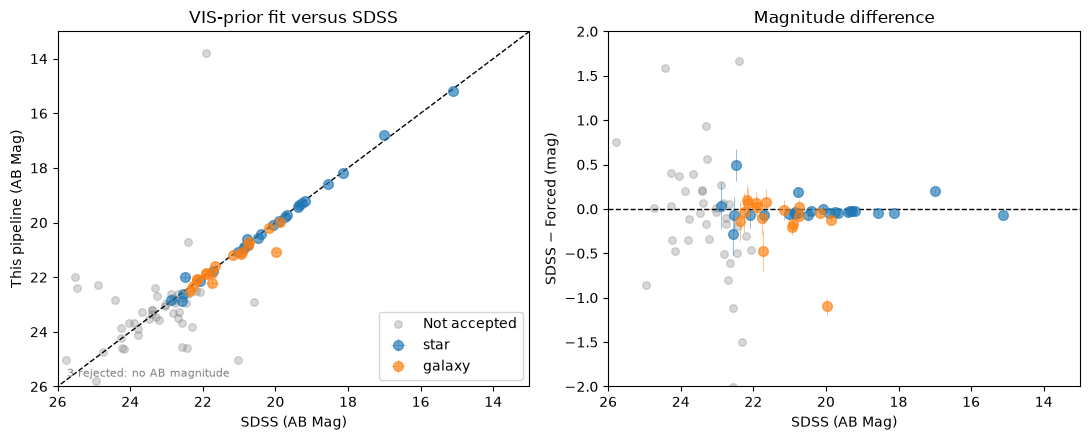

In [11]:
reference = Table.read(example.catalog)
comparison = gb.compare_sdss_g(fit.catalog, reference)

sdss_snr = comparison["reference_flux_ujy"]/comparison["reference_fluxerr_ujy"]
forced_snr = comparison["forced_flux_ujy"]/ comparison["forced_fluxerr_ujy"]
comparison["accepted"] = (
    (np.asarray(comparison["reference_clean"], int) == 1)
    &(np.asarray(comparison["separation_arcsec"], float) < 0.7)
    & ( sdss_snr > 5)
    & ( forced_snr > 5)   
    )
accepted = comparison[np.asarray(comparison["accepted"], bool)]
print(f"Clean SDSS matches: {len(accepted)} / {len(reference)} catalog rows")
for kind in ("star", "galaxy"):
    rows = accepted[accepted["source_type"] == kind]
    if len(rows):
        ratio = rows["forced_flux_ujy"] / rows["reference_flux_ujy"]
        print(f"{kind}: N={len(rows)}, median forced/SDSS={np.median(ratio):.3f}")
comparison.write(output / "catalog_comparison.ecsv", overwrite=True)
gb.show_catalog_comparison(comparison)
plt.show()

*Forced fluxes against the SDSS catalog. Blue stars and orange galaxies are matched within
0.7 arcsec with S/N above 5; the rest are gray.*

## 9. Inspect fitted sources and residuals

A look at the well-matched sources, from bright to faint: VIS, the ground image, the Tractor model, and the image minus the model.


Weighted residual RMS: 3.92


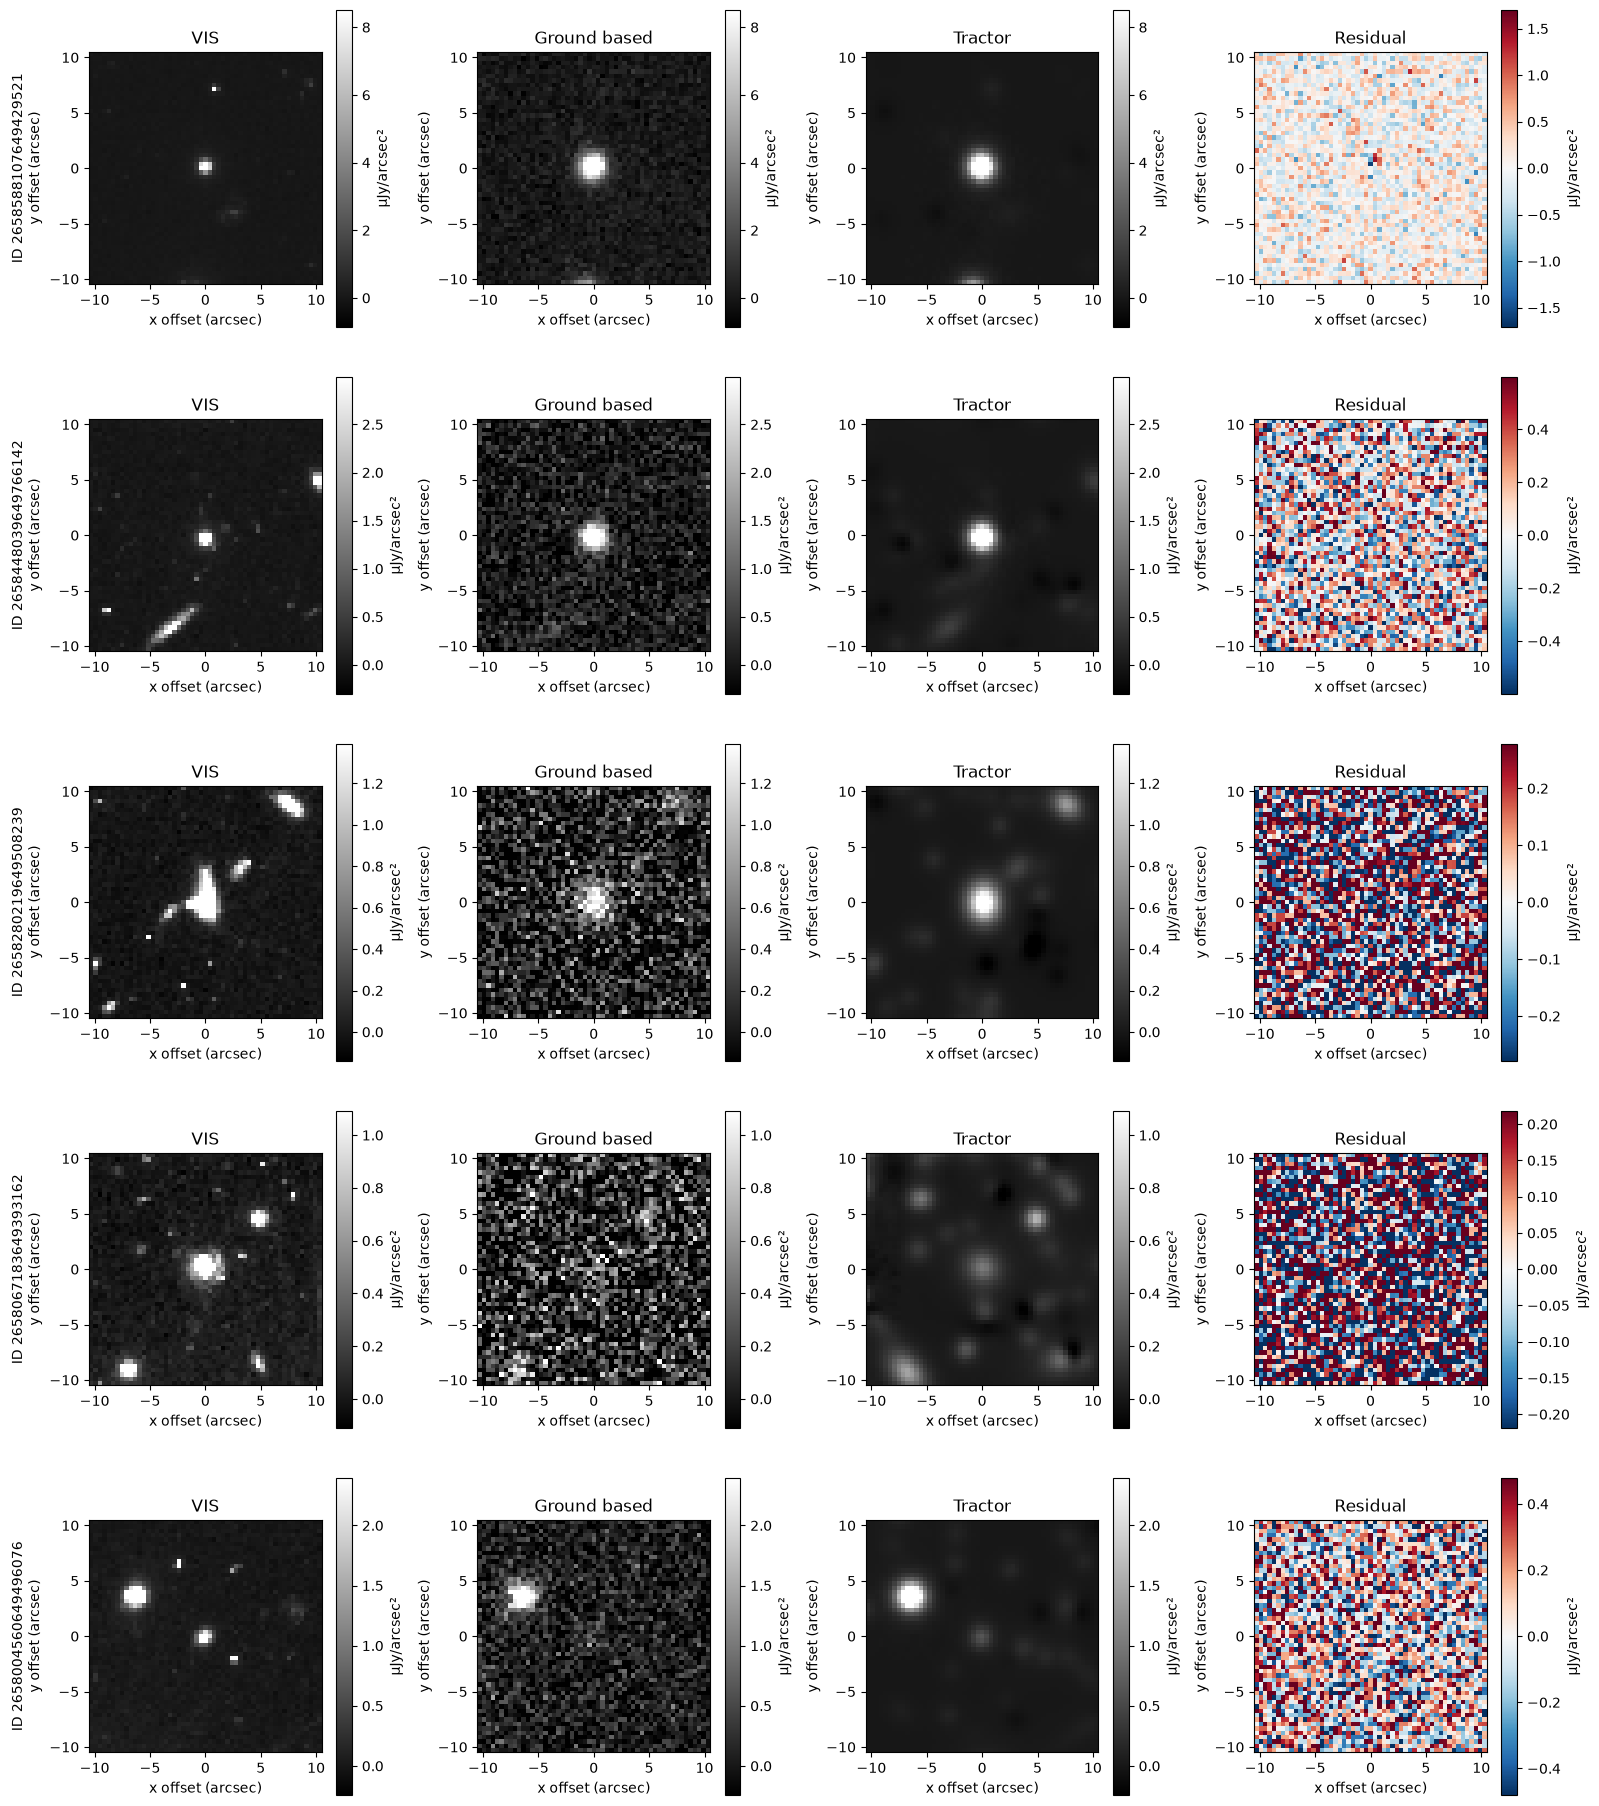

In [12]:
good = image.invvar_ujy > 0
weighted_rms = np.sqrt(np.mean(fit.residual[good]**2 * image.invvar_ujy[good]))
print(f"Weighted residual RMS: {weighted_rms:.2f}")
INSPECT_VMIN = None  # µJy/arcsec²; e.g. -0.05
INSPECT_VMAX = None  # µJy/arcsec²; e.g. 0.5
gb.show_fit_cutouts(fit, euclid.vis_cutout, size_arcsec=20, n_sources=5,
                    vmin=INSPECT_VMIN, vmax=INSPECT_VMAX)
plt.show()

*Well-matched sources from bright to faint: VIS, the ground image, the Tractor model, and the
image minus the model.*

## 10. Inspect mismatches

The same view for the sources where SDSS and the forced flux differ by more than 0.4 mag. The bright mismatches fall into three cases: galaxies at the edge of the image, a star saturated in VIS, and galaxies with lower S/N in SDSS.


Mismatches: 3; forced-flux underestimates: 2


euclid_object_id,source_type,sdss_minus_forced_mag,separation_arcsec
int64,str6,float64,float64
2658997107649930988,galaxy,-1.0981354176323528,0.11511621577269222


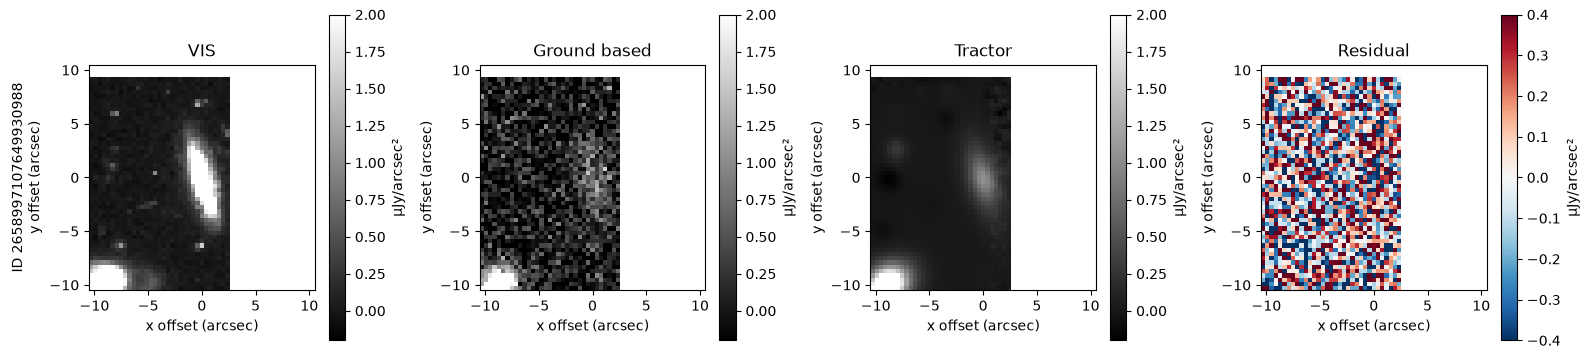

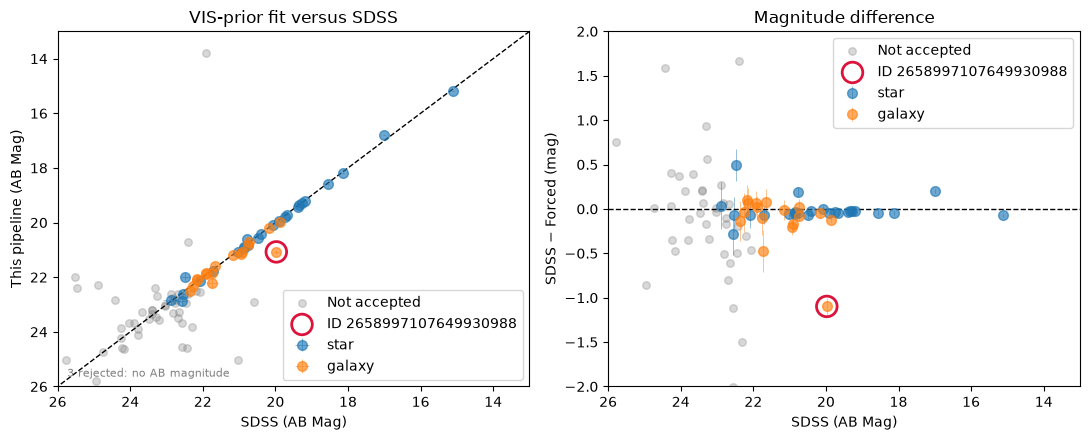

euclid_object_id,source_type,sdss_minus_forced_mag,separation_arcsec
int64,str6,float64,float64
2658006763649372939,star,0.4969029705243574,0.32432141049985563


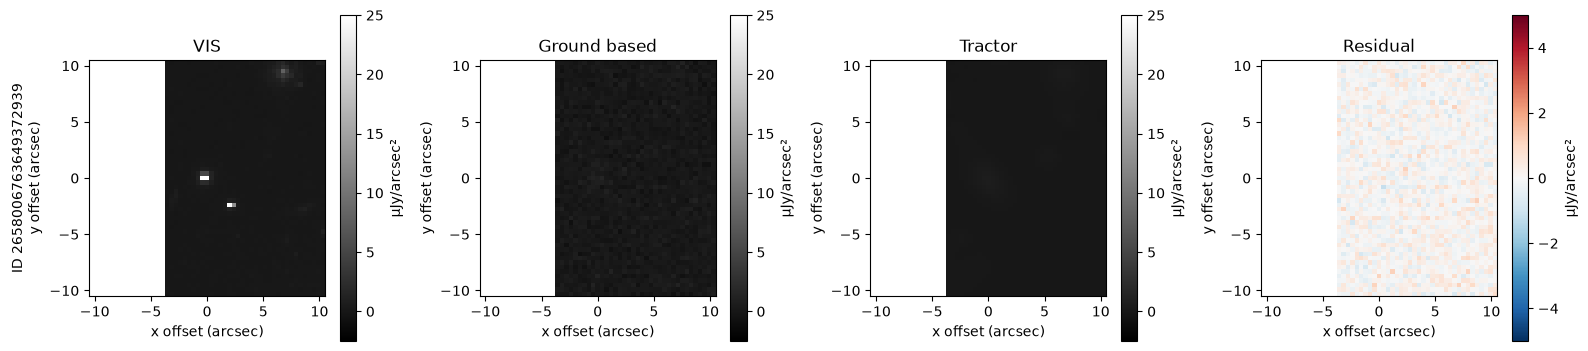

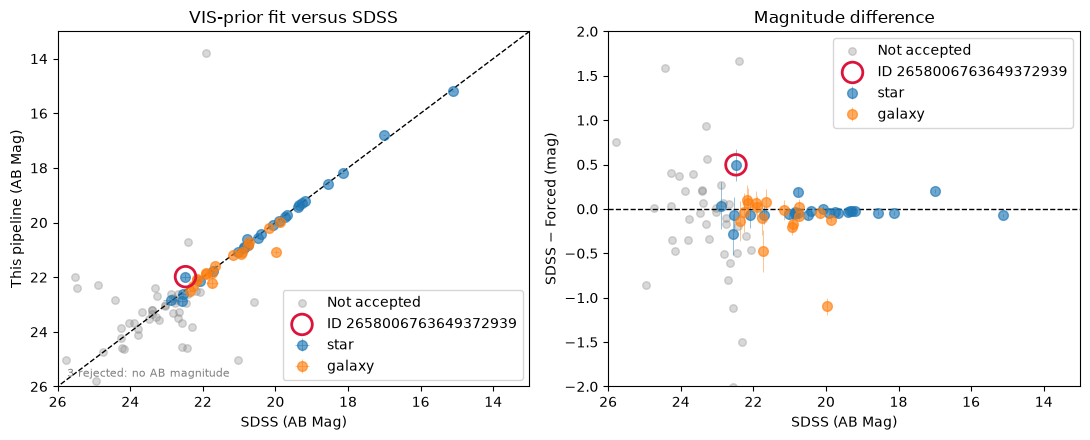

euclid_object_id,source_type,sdss_minus_forced_mag,separation_arcsec
int64,str6,float64,float64
2658396755649756800,galaxy,-0.4759723776711937,0.17407034824315942


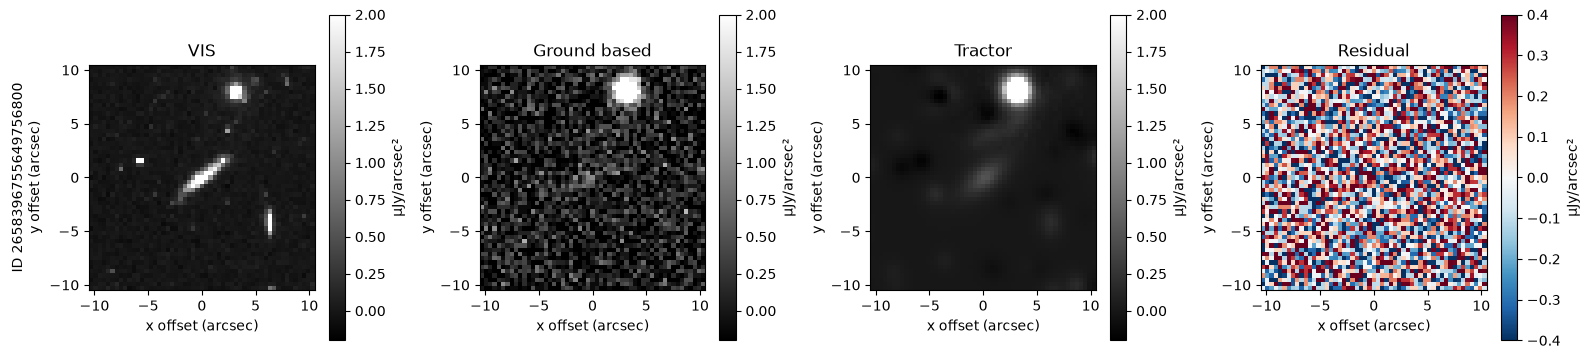

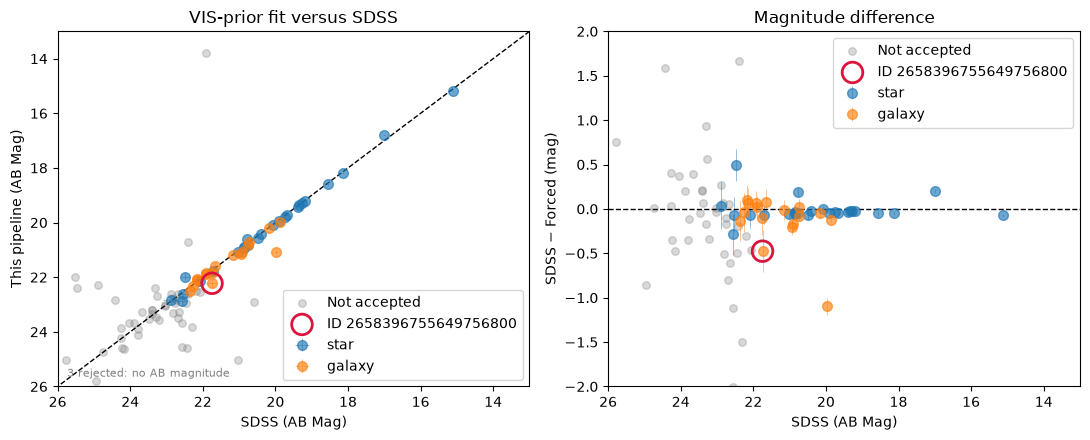

In [13]:
ref_flux = np.asarray(accepted["reference_flux_ujy"].data, dtype=float)
forced_flux = np.asarray(accepted["forced_flux_ujy"].data, dtype=float)
sdss_minus_forced = 2.5 * np.log10(forced_flux / ref_flux)
mismatch_rows = np.flatnonzero((np.abs(sdss_minus_forced) > 0.4))
mismatch_rows = mismatch_rows[np.argsort(np.abs(sdss_minus_forced[mismatch_rows]))[::-1]]
mismatches = accepted[mismatch_rows]
mismatches["sdss_minus_forced_mag"] = sdss_minus_forced[mismatch_rows]
print(f"Mismatches: {len(mismatches)}; forced-flux underestimates: "
      f"{np.count_nonzero(mismatches['sdss_minus_forced_mag'] < -0.4)}")

# One display maximum per mismatch, in the order listed below (µJy/arcsec²).
vmaxs = [2, 25, 2]

for i, vmax in zip(range(len(mismatches)), vmaxs):
    one = mismatches[i:i+1]
    object_id = int(one["euclid_object_id"].data[0])
    display(one["euclid_object_id", "source_type", "sdss_minus_forced_mag",
                "separation_arcsec"])
    gb.show_fit_cutouts(
        fit, euclid.vis_cutout, size_arcsec=20,
        object_ids=[object_id],
        vmin=None, vmax=vmax)
    plt.show()
    gb.show_catalog_comparison(comparison, highlight_object_id=object_id)
    plt.show()


*The sources where SDSS and the forced flux differ by more than 0.4 mag, in the same panels,
and where they fall on the comparison plot.*

## 11. Test sky subtraction with an injected background

To show what the background subtraction does, we add an artificial sky to the image, a second-order 2D polynomial plus uniform noise, then run the forced photometry with and without SEP background subtraction and compare both with the fluxes from the original, sky-free image.

The top row shows the injected sky, the sky SEP estimates, and the difference between them, which is the extra background SEP attributes to scattered light from stars. The bottom row shows the fit residuals before and after the subtraction, and the last panel compares both sets of fluxes with the sky-free ones.

Several objects come out fainter after subtraction because the scattered starlight has been removed from under them; SEP can also over-subtract where that scattered light is strong.


Two injected-image fits: 23.3 s
Injected polynomial sky: 0.024 to 0.105 µJy/pixel; uniform noise: -0.050 to 0.050 µJy/pixel


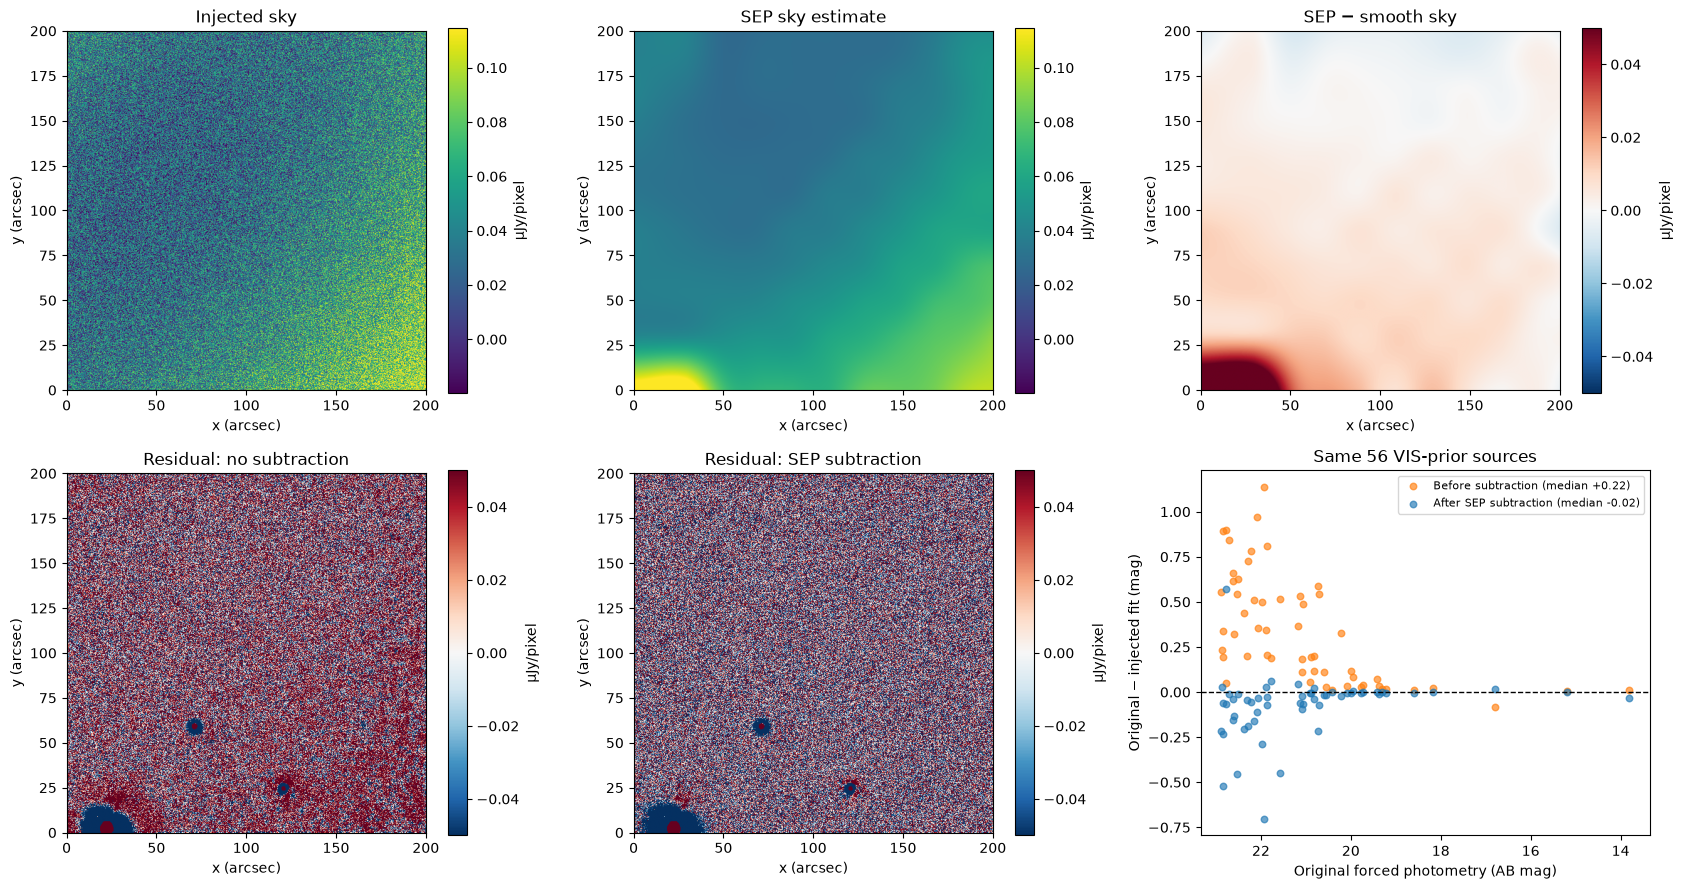

In [14]:
rng = np.random.default_rng(2026)
yy, xx = np.indices(image.science_ujy.shape, dtype=float)
xx = (xx - (nx - 1) / 2) / ((nx - 1) / 2)
yy = (yy - (ny - 1) / 2) / ((ny - 1) / 2)
mock_sky = (30 + 18*xx - 12*yy + 15*xx**2 - 16*xx*yy + 14*yy**2) * 1e-3  # µJy/pixel
extra_noise = rng.uniform(-0.05, 0.05, image.science_ujy.shape)
injected_ivar = np.zeros_like(image.invvar_ujy)
valid = image.invvar_ujy > 0
injected_ivar[valid] = 1 / (1 / image.invvar_ujy[valid])
injected_image = replace(image,
    science_ujy=image.science_ujy + mock_sky + extra_noise,
    invvar_ujy=injected_ivar)

sky_test_start = time.perf_counter()
no_sky = gb.fit_ground(
    injected_image, vis, background_method="none", psf_mode=PSF_MODE,
    psf_assessment=psf_check, excluded_psf_stars=EXCLUDE_PSF_STARS)
sep_sky = gb.fit_ground(
    injected_image, vis, background_method="sep", psf_mode=PSF_MODE,
    psf_assessment=psf_check, excluded_psf_stars=EXCLUDE_PSF_STARS)
print(f"Two injected-image fits: {time.perf_counter() - sky_test_start:.1f} s")
print(f"Injected polynomial sky: {mock_sky.min():.3f} to {mock_sky.max():.3f} µJy/pixel; "
      f"uniform noise: {extra_noise.min():.3f} to {extra_noise.max():.3f} µJy/pixel")
gb.show_sky_injection_test(
    mock_sky + extra_noise, fit, no_sky, sep_sky, smooth_sky=mock_sky,
    limit_ujy_per_pixel=0.05)
plt.show()


*Top: the injected sky, the SEP estimate of it, and their difference. Bottom: the fit residuals
before and after the subtraction, and both sets of fluxes against the sky-free fit.*